              precision    recall  f1-score   support

          AS       1.00      1.00      1.00        33
          MR       1.00      1.00      1.00        48
          MS       1.00      0.97      0.99        37
         MVP       0.97      1.00      0.99        38
      Normal       1.00      1.00      1.00        44

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



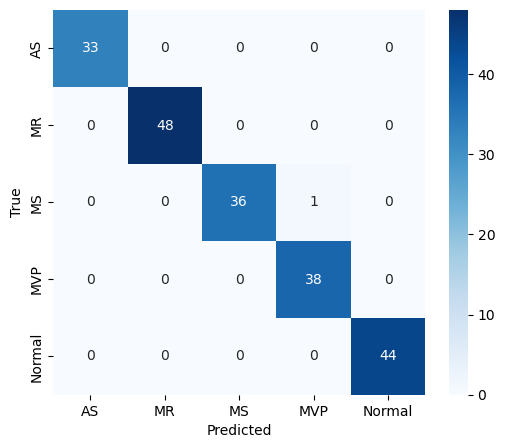

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load features ---
df = pd.read_csv("5Classesfeatures.csv")# add feature file name here to read it.
X = df.drop("label", axis=1)
y = df["label"]

# --- Train/Test split ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Classifier ---
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
plt.figure(figsize=(6, 5))  # adjust size if needed
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=clf.classes_, yticklabels=clf.classes_)

plt.xlabel("Predicted")
plt.ylabel("True")

# Save at 300 dpi
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()



===== Random Forest =====
              precision    recall  f1-score   support

          AS       1.00      1.00      1.00        33
          MR       1.00      1.00      1.00        48
          MS       1.00      0.97      0.99        37
         MVP       0.97      1.00      0.99        38
      Normal       1.00      1.00      1.00        44

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



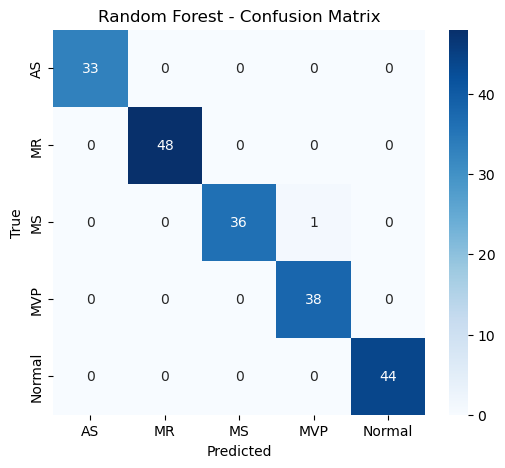



===== Decision Tree =====
              precision    recall  f1-score   support

          AS       0.94      0.88      0.91        33
          MR       0.96      0.92      0.94        48
          MS       0.90      0.95      0.92        37
         MVP       0.90      0.95      0.92        38
      Normal       1.00      1.00      1.00        44

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



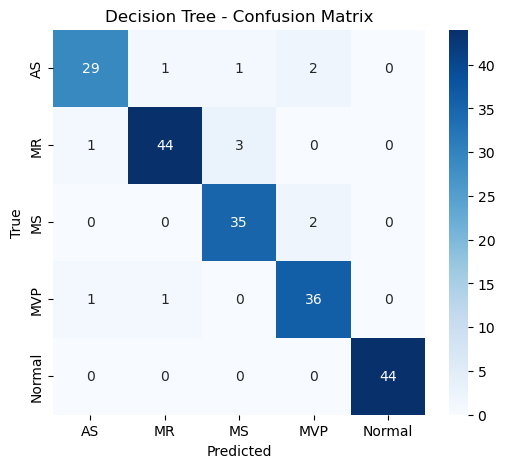



===== SVM =====
              precision    recall  f1-score   support

          AS       0.50      0.42      0.46        33
          MR       0.86      0.67      0.75        48
          MS       0.79      0.59      0.68        37
         MVP       0.47      0.74      0.57        38
      Normal       0.89      0.95      0.92        44

    accuracy                           0.69       200
   macro avg       0.70      0.68      0.68       200
weighted avg       0.72      0.69      0.69       200



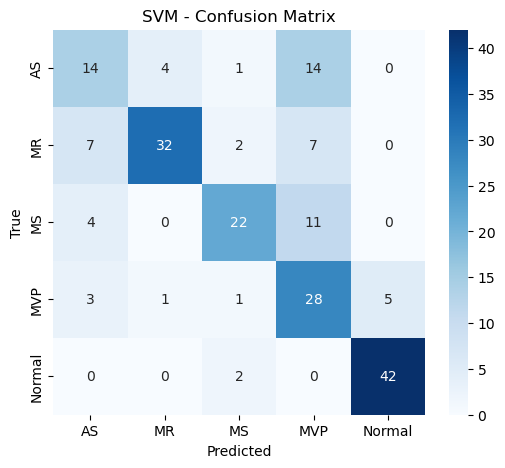



===== Gradient Boosting =====
              precision    recall  f1-score   support

          AS       1.00      0.97      0.98        33
          MR       1.00      0.96      0.98        48
          MS       1.00      0.95      0.97        37
         MVP       0.90      1.00      0.95        38
      Normal       0.98      1.00      0.99        44

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.98       200



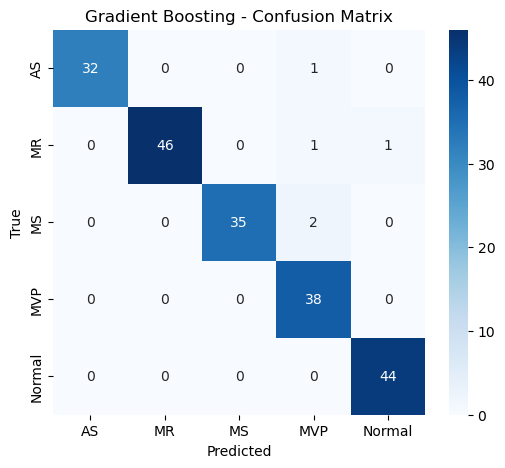

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load features ---
df = pd.read_csv("5Classesfeatures.csv")
X = df.drop("label", axis=1)
y = df["label"]

# --- Train/Test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- Define classifiers ---
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# --- Train and evaluate each model ---
for name, clf in classifiers.items():
    print(f"\n\n===== {name} =====")

    # Train
    clf.fit(X_train, y_train)

    # Predict
    y_pred = clf.predict(X_test)

    # Classification report
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=clf.classes_, yticklabels=clf.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")

    # Save figure
    plt.savefig(f"confusion_matrix_{name.replace(' ', '_')}.png",
                dpi=300, bbox_inches="tight")

    plt.show()
